# ETL y exploración del dataset Face Mask Detection

Este notebook documenta la lectura, validación y transformación de las imágenes y anotaciones PASCAL VOC para construir un dataset de clasificación de rostros.

In [2]:
from pathlib import Path

# La ruta funciona si Jupyter inicia en la raíz o en notebooks.
ruta_actual = Path.cwd()

if ruta_actual.name == "notebooks":
    BASE = ruta_actual.parent
else:
    BASE = ruta_actual

IMAGES_DIR = BASE / "data" / "raw" / "images"
ANNOTATIONS_DIR = BASE / "data" / "raw" / "annotations"

imagenes = sorted(IMAGES_DIR.glob("*.png"))
anotaciones = sorted(ANNOTATIONS_DIR.glob("*.xml"))

print("Carpeta del proyecto:", BASE)
print("Existe images:", IMAGES_DIR.exists())
print("Existe annotations:", ANNOTATIONS_DIR.exists())
print("Cantidad de imágenes:", len(imagenes))
print("Cantidad de XML:", len(anotaciones))
print("Primera imagen:", imagenes[0].name)
print("Primer XML:", anotaciones[0].name)

assert IMAGES_DIR.exists(), "No se encontró la carpeta images"
assert ANNOTATIONS_DIR.exists(), "No se encontró la carpeta annotations"
assert len(imagenes) == 853, "La cantidad de imágenes no coincide"
assert len(anotaciones) == 853, "La cantidad de XML no coincide"

Carpeta del proyecto: /Users/eduardoabundiz/Desktop/face_mask_detection
Existe images: True
Existe annotations: True
Cantidad de imágenes: 853
Cantidad de XML: 853
Primera imagen: maksssksksss0.png
Primer XML: maksssksksss0.xml


## 1. Comprensión de las anotaciones XML

Cada XML describe una imagen y contiene uno o más objetos. Cada objeto representa un rostro, su clase y las coordenadas de su cuadro delimitador.

In [3]:
import xml.etree.ElementTree as ET
import pandas as pd

# Buscar de forma determinista el primer XML con al menos tres rostros.
xml_ejemplo = None

for ruta_xml in anotaciones:
    raiz_temporal = ET.parse(ruta_xml).getroot()
    objetos_temporales = raiz_temporal.findall("object")

    if len(objetos_temporales) >= 3:
        xml_ejemplo = ruta_xml
        break

assert xml_ejemplo is not None, "No se encontró un XML con tres rostros"

# Leer nuevamente el XML seleccionado.
raiz = ET.parse(xml_ejemplo).getroot()

nombre_imagen = raiz.findtext("filename")

elemento_size = raiz.find("size")
ancho_declarado = int(elemento_size.findtext("width"))
alto_declarado = int(elemento_size.findtext("height"))
canales_declarados = int(elemento_size.findtext("depth"))

registros = []

for numero, objeto in enumerate(raiz.findall("object"), start=1):
    clase = objeto.findtext("name")
    caja = objeto.find("bndbox")

    registros.append({
        "objeto": numero,
        "clase": clase,
        "xmin": int(caja.findtext("xmin")),
        "ymin": int(caja.findtext("ymin")),
        "xmax": int(caja.findtext("xmax")),
        "ymax": int(caja.findtext("ymax")),
    })

tabla_objetos = pd.DataFrame(registros)

print("XML seleccionado:", xml_ejemplo.name)
print("Imagen correspondiente:", nombre_imagen)
print(
    "Tamaño declarado:",
    ancho_declarado,
    "x",
    alto_declarado,
    "| Canales:",
    canales_declarados,
)
print("Cantidad de rostros:", len(tabla_objetos))

display(tabla_objetos)

XML seleccionado: maksssksksss0.xml
Imagen correspondiente: maksssksksss0.png
Tamaño declarado: 512 x 366 | Canales: 3
Cantidad de rostros: 3


,objeto,clase,xmin,ymin,xmax,ymax
0,1,without_mask,79,105,109,142
1,2,with_mask,185,100,226,144
2,3,without_mask,325,90,360,141


Ruta: /Users/eduardoabundiz/Desktop/face_mask_detection/data/raw/images/maksssksksss0.png
Formato: PNG
Modo original: RGB
Tamaño real: (512, 366)
Tamaño declarado: (512, 366)


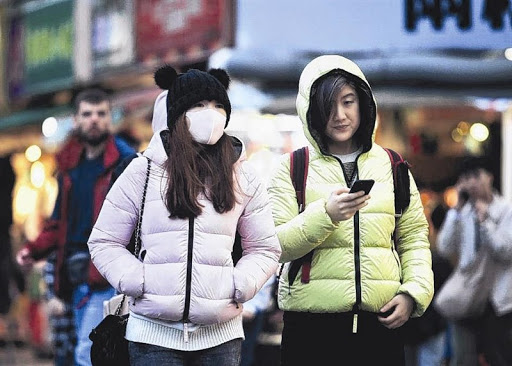

In [4]:
from PIL import Image

ruta_imagen_ejemplo = IMAGES_DIR / nombre_imagen

assert ruta_imagen_ejemplo.exists(), (
    f"No se encontró la imagen {nombre_imagen}"
)

with Image.open(ruta_imagen_ejemplo) as imagen:
    formato_original = imagen.format
    modo_original = imagen.mode
    tamaño_real = imagen.size
    imagen_rgb = imagen.convert("RGB")

print("Ruta:", ruta_imagen_ejemplo)
print("Formato:", formato_original)
print("Modo original:", modo_original)
print("Tamaño real:", tamaño_real)
print("Tamaño declarado:", (ancho_declarado, alto_declarado))

assert tamaño_real == (ancho_declarado, alto_declarado), (
    "El tamaño real no coincide con el XML"
)

display(imagen_rgb)

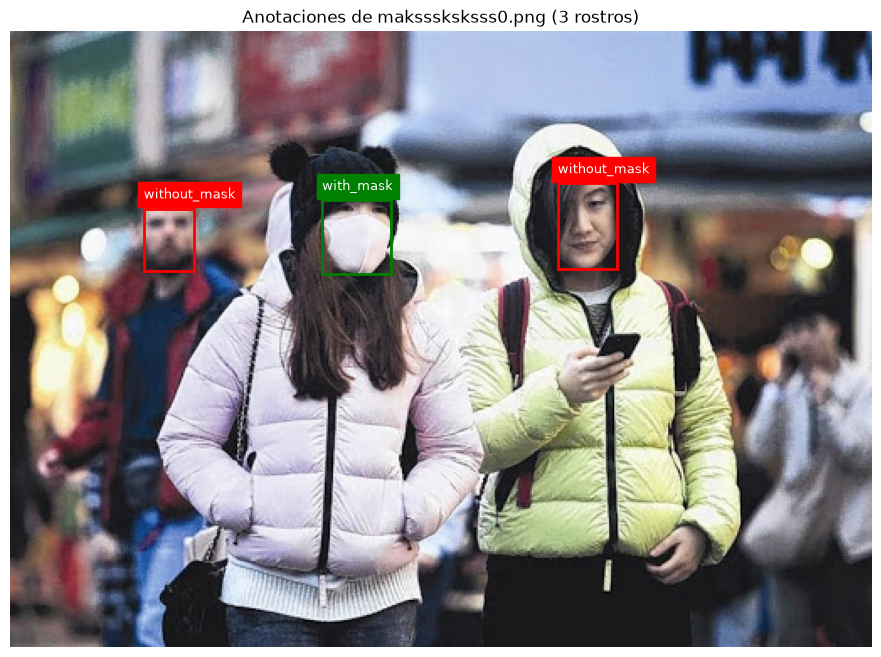

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

colores = {
    "with_mask": "green",
    "without_mask": "red",
    "mask_weared_incorrect": "orange",
}

figura, eje = plt.subplots(figsize=(12, 8))

eje.imshow(imagen_rgb)

for fila in tabla_objetos.itertuples(index=False):
    ancho_caja = fila.xmax - fila.xmin
    alto_caja = fila.ymax - fila.ymin

    color = colores[fila.clase]

    rectangulo = Rectangle(
        (fila.xmin, fila.ymin),
        ancho_caja,
        alto_caja,
        linewidth=2,
        edgecolor=color,
        facecolor="none",
    )

    eje.add_patch(rectangulo)

    eje.text(
        fila.xmin,
        max(fila.ymin - 6, 0),
        fila.clase,
        color="white",
        fontsize=9,
        backgroundcolor=color,
    )

eje.set_title(
    f"Anotaciones de {nombre_imagen} "
    f"({len(tabla_objetos)} rostros)"
)
eje.axis("off")

plt.show()

## 2. Inventario general de las anotaciones

Se revisan todos los XML para conocer la cantidad de rostros, distribución de clases, imágenes con múltiples objetos y posibles coordenadas inválidas.

In [6]:
from collections import Counter

CLASES_VALIDAS = {
    "with_mask",
    "without_mask",
    "mask_weared_incorrect",
}

registros_generales = []
objetos_por_imagen = Counter()
imagenes_faltantes = []
clases_desconocidas = []
cajas_fuera_del_borde = []
cajas_sin_area = []

for ruta_xml in anotaciones:
    raiz = ET.parse(ruta_xml).getroot()

    nombre_imagen_xml = raiz.findtext("filename")
    ruta_imagen = IMAGES_DIR / nombre_imagen_xml

    elemento_size = raiz.find("size")
    ancho = int(elemento_size.findtext("width"))
    alto = int(elemento_size.findtext("height"))

    objetos = raiz.findall("object")
    objetos_por_imagen[len(objetos)] += 1

    if not ruta_imagen.exists():
        imagenes_faltantes.append(nombre_imagen_xml)

    for numero_objeto, objeto in enumerate(objetos, start=1):
        clase = objeto.findtext("name")
        caja = objeto.find("bndbox")

        xmin = int(caja.findtext("xmin"))
        ymin = int(caja.findtext("ymin"))
        xmax = int(caja.findtext("xmax"))
        ymax = int(caja.findtext("ymax"))

        if clase not in CLASES_VALIDAS:
            clases_desconocidas.append({
                "xml": ruta_xml.name,
                "clase": clase,
            })

        if xmin >= xmax or ymin >= ymax:
            cajas_sin_area.append({
                "xml": ruta_xml.name,
                "objeto": numero_objeto,
                "coordenadas": (xmin, ymin, xmax, ymax),
            })

        if (
            xmin < 0
            or ymin < 0
            or xmax > ancho
            or ymax > alto
        ):
            cajas_fuera_del_borde.append({
                "xml": ruta_xml.name,
                "imagen": nombre_imagen_xml,
                "clase": clase,
                "ancho_imagen": ancho,
                "alto_imagen": alto,
                "xmin": xmin,
                "ymin": ymin,
                "xmax": xmax,
                "ymax": ymax,
            })

        registros_generales.append({
            "xml_original": ruta_xml.name,
            "imagen_original": nombre_imagen_xml,
            "numero_objeto": numero_objeto,
            "ancho_imagen": ancho,
            "alto_imagen": alto,
            "clase": clase,
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax,
        })

metadata_inicial = pd.DataFrame(registros_generales)

conteo_clases = (
    metadata_inicial["clase"]
    .value_counts()
    .rename_axis("clase")
    .reset_index(name="rostros")
)

conteo_clases["porcentaje"] = (
    conteo_clases["rostros"]
    / len(metadata_inicial)
    * 100
).round(2)

imagenes_con_varios_rostros = sum(
    cantidad_imagenes
    for numero_objetos, cantidad_imagenes
    in objetos_por_imagen.items()
    if numero_objetos > 1
)

print("XML analizados:", len(anotaciones))
print("Rostros encontrados:", len(metadata_inicial))
print(
    "Imágenes con más de un rostro:",
    imagenes_con_varios_rostros,
)
print("Imágenes faltantes:", len(imagenes_faltantes))
print("Clases desconocidas:", len(clases_desconocidas))
print("Cajas sin área:", len(cajas_sin_area))
print(
    "Cajas que exceden los límites:",
    len(cajas_fuera_del_borde),
)

print("\nDistribución de clases:")
display(conteo_clases)

print("\nDistribución del número de rostros por imagen:")
display(
    pd.DataFrame(
        sorted(objetos_por_imagen.items()),
        columns=["rostros_en_imagen", "cantidad_imagenes"],
    )
)

XML analizados: 853
Rostros encontrados: 4072
Imágenes con más de un rostro: 524
Imágenes faltantes: 0
Clases desconocidas: 0
Cajas sin área: 0
Cajas que exceden los límites: 12

Distribución de clases:


,clase,rostros,porcentaje
0,with_mask,3232,79.37
1,without_mask,717,17.61
2,mask_weared_incorrect,123,3.02



Distribución del número de rostros por imagen:


,rostros_en_imagen,cantidad_imagenes
0,1,329
1,2,100
2,3,68
3,4,83
4,5,49
5,6,37
6,7,24
7,8,34
8,9,22
9,10,17


In [7]:
cajas_fuera_df = pd.DataFrame(cajas_fuera_del_borde)

cajas_fuera_df["exceso_xmax"] = (
    cajas_fuera_df["xmax"]
    - cajas_fuera_df["ancho_imagen"]
).clip(lower=0)

cajas_fuera_df["exceso_ymax"] = (
    cajas_fuera_df["ymax"]
    - cajas_fuera_df["alto_imagen"]
).clip(lower=0)

print("Cantidad de cajas fuera del borde:", len(cajas_fuera_df))

print(
    "Máximo exceso horizontal:",
    cajas_fuera_df["exceso_xmax"].max(),
)

print(
    "Máximo exceso vertical:",
    cajas_fuera_df["exceso_ymax"].max(),
)

display(
    cajas_fuera_df[
        [
            "xml",
            "imagen",
            "clase",
            "ancho_imagen",
            "alto_imagen",
            "xmin",
            "ymin",
            "xmax",
            "ymax",
            "exceso_xmax",
            "exceso_ymax",
        ]
    ]
)

Cantidad de cajas fuera del borde: 12
Máximo exceso horizontal: 1
Máximo exceso vertical: 0


,xml,imagen,clase,ancho_imagen,alto_imagen,xmin,ymin,xmax,ymax,exceso_xmax,exceso_ymax
0,maksssksksss110.xml,maksssksksss110.png,without_mask,400,267,381,14,401,34,1,0
1,maksssksksss231.xml,maksssksksss231.png,with_mask,400,249,392,86,401,106,1,0
2,maksssksksss251.xml,maksssksksss251.png,with_mask,400,206,373,76,401,114,1,0
3,maksssksksss457.xml,maksssksksss457.png,with_mask,400,300,389,56,401,83,1,0
4,maksssksksss5.xml,maksssksksss5.png,without_mask,400,266,364,30,401,66,1,0
5,maksssksksss501.xml,maksssksksss501.png,with_mask,400,255,357,65,401,132,1,0
6,maksssksksss603.xml,maksssksksss603.png,with_mask,400,278,397,132,401,142,1,0
7,maksssksksss603.xml,maksssksksss603.png,without_mask,400,278,396,18,401,23,1,0
8,maksssksksss616.xml,maksssksksss616.png,with_mask,400,267,394,92,401,111,1,0
9,maksssksksss706.xml,maksssksksss706.png,with_mask,400,267,368,162,401,219,1,0


In [8]:
# Copia temporal para el análisis exploratorio
analisis_tamanos = metadata_inicial.copy()

# Coordenadas válidas utilizadas solo para calcular tamaños
analisis_tamanos["xmax_analisis"] = analisis_tamanos[
    ["xmax", "ancho_imagen"]
].min(axis=1)

analisis_tamanos["ymax_analisis"] = analisis_tamanos[
    ["ymax", "alto_imagen"]
].min(axis=1)

analisis_tamanos["xmin_analisis"] = (
    analisis_tamanos["xmin"].clip(lower=0)
)

analisis_tamanos["ymin_analisis"] = (
    analisis_tamanos["ymin"].clip(lower=0)
)

# Tamaño de cada caja
analisis_tamanos["ancho_rostro"] = (
    analisis_tamanos["xmax_analisis"]
    - analisis_tamanos["xmin_analisis"]
)

analisis_tamanos["alto_rostro"] = (
    analisis_tamanos["ymax_analisis"]
    - analisis_tamanos["ymin_analisis"]
)

analisis_tamanos["area_rostro"] = (
    analisis_tamanos["ancho_rostro"]
    * analisis_tamanos["alto_rostro"]
)

print("Resumen del tamaño de los rostros:")

display(
    analisis_tamanos[
        ["ancho_rostro", "alto_rostro", "area_rostro"]
    ].describe(
        percentiles=[
            0.01, 0.05, 0.10, 0.25,
            0.50, 0.75, 0.90
        ]
    )
)

print("\nCantidad de rostros pequeños:")

for limite in [10, 15, 20, 25]:
    cantidad = (
        (analisis_tamanos["ancho_rostro"] < limite)
        | (analisis_tamanos["alto_rostro"] < limite)
    ).sum()

    porcentaje = 100 * cantidad / len(analisis_tamanos)

    print(
        f"Menores de {limite} píxeles: "
        f"{cantidad} ({porcentaje:.2f}%)"
    )

Resumen del tamaño de los rostros:


,ancho_rostro,alto_rostro,area_rostro
count,4072.000000,4072.000000,4072.000000
mean,31.146120,35.004912,1977.970530
std,27.960328,32.635004,4693.437916
min,1.000000,2.000000,2.000000
1%,5.000000,6.000000,30.000000
5%,7.000000,8.000000,63.000000
10%,9.000000,10.000000,99.000000
25%,14.000000,16.000000,225.000000
50%,22.000000,24.000000,528.000000
75%,36.000000,40.000000,1369.000000



Cantidad de rostros pequeños:
Menores de 10 píxeles: 469 (11.52%)
Menores de 15 píxeles: 1136 (27.90%)
Menores de 20 píxeles: 1821 (44.72%)
Menores de 25 píxeles: 2374 (58.30%)


In [9]:
analisis_tamanos["dimension_minima"] = analisis_tamanos[
    ["ancho_rostro", "alto_rostro"]
].min(axis=1)

print("Tamaño de los rostros por clase:")

resumen_por_clase = (
    analisis_tamanos
    .groupby("clase")
    .agg(
        rostros=("clase", "size"),
        ancho_promedio=("ancho_rostro", "mean"),
        ancho_mediano=("ancho_rostro", "median"),
        alto_promedio=("alto_rostro", "mean"),
        alto_mediano=("alto_rostro", "median"),
        dimension_minima_mediana=("dimension_minima", "median"),
    )
    .round(2)
)

display(resumen_por_clase)

for limite in [10, 15, 20]:
    pequeños = (
        analisis_tamanos["dimension_minima"] < limite
    )

    comparacion = pd.crosstab(
        analisis_tamanos["clase"],
        pequeños,
    )

    comparacion = comparacion.rename(
        columns={
            False: "conservados",
            True: "menores_limite",
        }
    )

    if "conservados" not in comparacion.columns:
        comparacion["conservados"] = 0

    if "menores_limite" not in comparacion.columns:
        comparacion["menores_limite"] = 0

    comparacion["total"] = (
        comparacion["conservados"]
        + comparacion["menores_limite"]
    )

    comparacion["porcentaje_menor"] = (
        100
        * comparacion["menores_limite"]
        / comparacion["total"]
    ).round(2)

    print(f"\nLímite analizado: {limite} píxeles")
    display(comparacion)

Tamaño de los rostros por clase:


,rostros,ancho_promedio,ancho_mediano,alto_promedio,alto_mediano,dimension_minima_mediana
clase,,,,,,
mask_weared_incorrect,123,38.41,27.0,42.85,31.0,27.0
with_mask,3232,31.91,23.0,35.72,25.0,22.0
without_mask,717,26.46,18.0,30.42,20.0,18.0



Límite analizado: 10 píxeles


dimension_minima,conservados,menores_limite,total,porcentaje_menor
clase,,,,
mask_weared_incorrect,118,5,123,4.07
with_mask,2877,355,3232,10.98
without_mask,608,109,717,15.20



Límite analizado: 15 píxeles


dimension_minima,conservados,menores_limite,total,porcentaje_menor
clase,,,,
mask_weared_incorrect,98,25,123,20.33
with_mask,2394,838,3232,25.93
without_mask,444,273,717,38.08



Límite analizado: 20 píxeles


dimension_minima,conservados,menores_limite,total,porcentaje_menor
clase,,,,
mask_weared_incorrect,81,42,123,34.15
with_mask,1854,1378,3232,42.64
without_mask,316,401,717,55.93


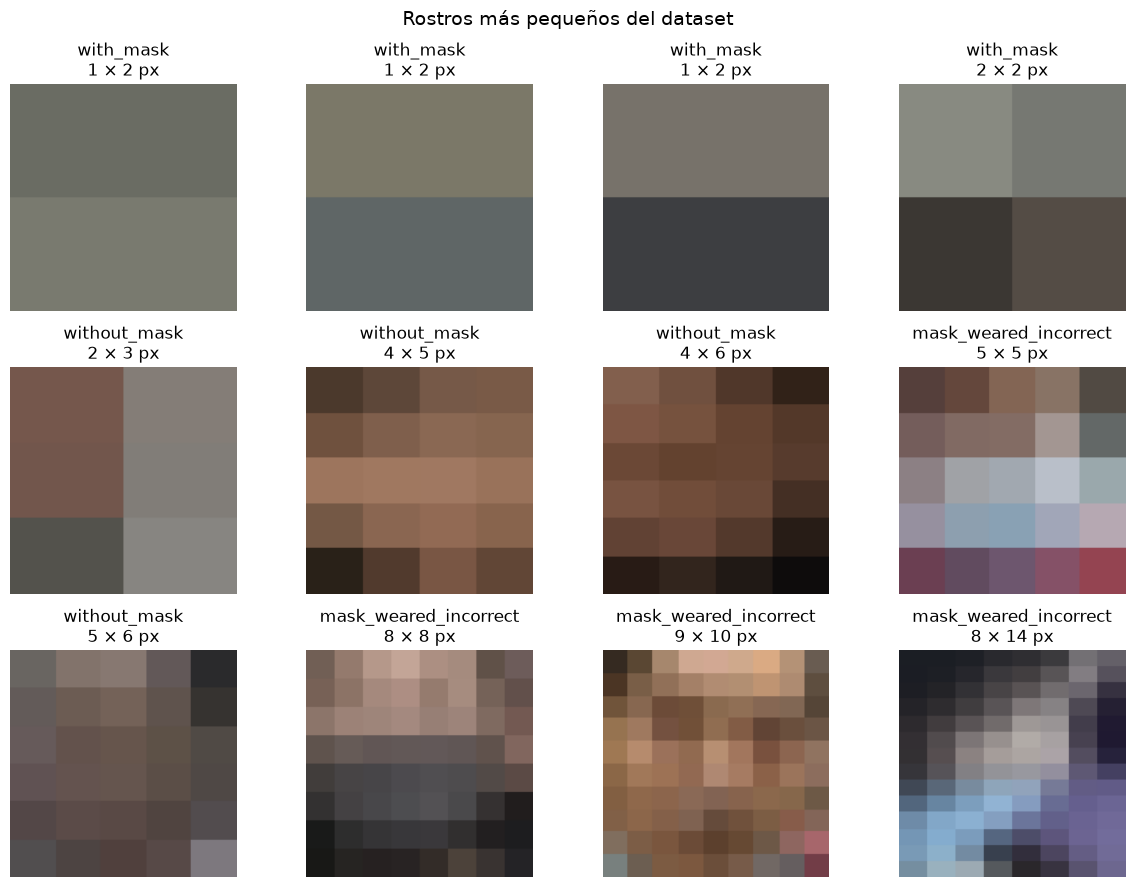

In [10]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

carpeta_imagenes = Path(
    "/Users/eduardoabundiz/Desktop/"
    "face_mask_detection/data/raw/images"
)

# Seleccionar cuatro casos pequeños por clase
muestras_pequenas = (
    analisis_tamanos[
        analisis_tamanos["dimension_minima"] < 10
    ]
    .sort_values("area_rostro")
    .groupby("clase", group_keys=False)
    .head(4)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(12, 9),
)

axes = axes.flatten()

for eje, (_, fila) in zip(
    axes,
    muestras_pequenas.iterrows(),
):
    ruta_imagen = carpeta_imagenes / fila["imagen_original"]

    with Image.open(ruta_imagen) as imagen:
        imagen = imagen.convert("RGB")

        caja = (
            int(fila["xmin_analisis"]),
            int(fila["ymin_analisis"]),
            int(fila["xmax_analisis"]),
            int(fila["ymax_analisis"]),
        )

        rostro = imagen.crop(caja)

        # Ampliación para observar los píxeles disponibles
        rostro_ampliado = rostro.resize(
            (128, 128),
            Image.Resampling.NEAREST,
        )

    eje.imshow(rostro_ampliado)
    eje.set_title(
        f'{fila["clase"]}\n'
        f'{fila["ancho_rostro"]} × '
        f'{fila["alto_rostro"]} px'
    )
    eje.axis("off")

for eje in axes[len(muestras_pequenas):]:
    eje.axis("off")

plt.suptitle(
    "Rostros más pequeños del dataset",
    fontsize=14,
)

plt.tight_layout()
plt.show()

In [11]:
from PIL import Image
import pandas as pd

imagenes_unicas = (
    metadata_inicial[
        [
            "imagen_original",
            "ancho_imagen",
            "alto_imagen",
        ]
    ]
    .drop_duplicates(subset="imagen_original")
    .reset_index(drop=True)
)

inventario_imagenes = []
errores_lectura = []

for _, fila in imagenes_unicas.iterrows():
    ruta_imagen = (
        carpeta_imagenes / fila["imagen_original"]
    )

    try:
        with Image.open(ruta_imagen) as imagen:
            ancho_real, alto_real = imagen.size

            inventario_imagenes.append(
                {
                    "imagen": fila["imagen_original"],
                    "formato": imagen.format,
                    "modo": imagen.mode,
                    "ancho_real": ancho_real,
                    "alto_real": alto_real,
                    "ancho_xml": fila["ancho_imagen"],
                    "alto_xml": fila["alto_imagen"],
                    "coincide_xml": (
                        ancho_real == fila["ancho_imagen"]
                        and alto_real == fila["alto_imagen"]
                    ),
                }
            )

    except Exception as error:
        errores_lectura.append(
            {
                "imagen": fila["imagen_original"],
                "error": str(error),
            }
        )

inventario_imagenes = pd.DataFrame(inventario_imagenes)
errores_lectura = pd.DataFrame(errores_lectura)

print("Imágenes revisadas:", len(inventario_imagenes))
print("Errores de lectura:", len(errores_lectura))
print(
    "Dimensiones distintas entre XML e imagen:",
    (~inventario_imagenes["coincide_xml"]).sum(),
)

print("\nFormatos:")
display(
    inventario_imagenes["formato"]
    .value_counts()
    .rename_axis("formato")
    .reset_index(name="imagenes")
)

print("\nModos de color:")
display(
    inventario_imagenes["modo"]
    .value_counts()
    .rename_axis("modo")
    .reset_index(name="imagenes")
)

print("\nDimensiones más frecuentes:")
display(
    inventario_imagenes[
        ["ancho_real", "alto_real"]
    ]
    .value_counts()
    .head(15)
    .reset_index(name="imagenes")
)

print("\nResumen de dimensiones:")
display(
    inventario_imagenes[
        ["ancho_real", "alto_real"]
    ].describe()
)

Imágenes revisadas: 853
Errores de lectura: 0
Dimensiones distintas entre XML e imagen: 0

Formatos:


,formato,imagenes
0,PNG,853



Modos de color:


,modo,imagenes
0,RGBA,831
1,RGB,22



Dimensiones más frecuentes:


,ancho_real,alto_real,imagenes
0,301,400,184
1,400,267,143
2,400,225,88
3,400,300,51
4,400,226,50
5,267,400,44
6,400,400,24
7,400,268,14
8,400,210,14
9,400,200,10



Resumen de dimensiones:


,ancho_real,alto_real
count,853.000000,853.000000
mean,370.589683,309.289566
std,56.224049,74.474840
min,193.000000,156.000000
25%,301.000000,254.000000
50%,400.000000,280.000000
75%,400.000000,400.000000
max,600.000000,600.000000


In [12]:
import numpy as np

analisis_alpha = []

imagenes_rgba = inventario_imagenes[
    inventario_imagenes["modo"] == "RGBA"
]

for nombre_imagen in imagenes_rgba["imagen"]:
    ruta_imagen = carpeta_imagenes / nombre_imagen

    with Image.open(ruta_imagen) as imagen:
        canal_alpha = np.asarray(
            imagen.getchannel("A")
        )

        pixeles_no_opacos = int(
            np.sum(canal_alpha < 255)
        )

        analisis_alpha.append(
            {
                "imagen": nombre_imagen,
                "alpha_minimo": int(canal_alpha.min()),
                "alpha_maximo": int(canal_alpha.max()),
                "pixeles_no_opacos": pixeles_no_opacos,
                "tiene_transparencia": (
                    pixeles_no_opacos > 0
                ),
            }
        )

analisis_alpha = pd.DataFrame(analisis_alpha)

print("Imágenes RGBA:", len(analisis_alpha))

print(
    "Imágenes con transparencia real:",
    analisis_alpha["tiene_transparencia"].sum(),
)

print(
    "Valor alfa mínimo encontrado:",
    analisis_alpha["alpha_minimo"].min(),
)

print("\nImágenes con mayor cantidad de píxeles no opacos:")

display(
    analisis_alpha.sort_values(
        "pixeles_no_opacos",
        ascending=False,
    ).head(10)
)

Imágenes RGBA: 831
Imágenes con transparencia real: 638
Valor alfa mínimo encontrado: 0

Imágenes con mayor cantidad de píxeles no opacos:


,imagen,alpha_minimo,alpha_maximo,pixeles_no_opacos,tiene_transparencia
447,maksssksksss510.png,161,255,670,True
54,maksssksksss15.png,229,255,451,True
0,maksssksksss1.png,216,255,400,True
527,maksssksksss586.png,103,255,400,True
517,maksssksksss577.png,170,255,400,True
518,maksssksksss578.png,103,255,400,True
519,maksssksksss579.png,23,255,400,True
520,maksssksksss58.png,170,255,400,True
521,maksssksksss580.png,170,255,400,True
522,maksssksksss581.png,132,255,400,True


In [13]:
rostros_conservados = analisis_tamanos[
    analisis_tamanos["dimension_minima"] >= 10
]

transparencia_en_rostros = []

for _, fila in rostros_conservados.iterrows():
    ruta = carpeta_imagenes / fila["imagen_original"]

    with Image.open(ruta) as imagen:
        caja = (
            int(fila["xmin_analisis"]),
            int(fila["ymin_analisis"]),
            int(fila["xmax_analisis"]),
            int(fila["ymax_analisis"]),
        )
        recorte = imagen.crop(caja)

        if recorte.mode == "RGBA":
            alfa = np.asarray(recorte.getchannel("A"))
            pixeles_transparentes = int((alfa < 255).sum())
        else:
            pixeles_transparentes = 0

    transparencia_en_rostros.append({
        "imagen": fila["imagen_original"],
        "clase": fila["clase"],
        "pixeles_no_opacos": pixeles_transparentes,
    })

transparencia_en_rostros = pd.DataFrame(transparencia_en_rostros)

print("Rostros examinados:", len(transparencia_en_rostros))
print(
    "Rostros con alguna transparencia:",
    (transparencia_en_rostros["pixeles_no_opacos"] > 0).sum()
)

display(
    transparencia_en_rostros.sort_values(
        "pixeles_no_opacos", ascending=False
    ).head(10)
)

Rostros examinados: 3603
Rostros con alguna transparencia: 6


,imagen,clase,pixeles_no_opacos
1245,maksssksksss347.png,without_mask,105
439,maksssksksss200.png,with_mask,101
159,maksssksksss126.png,without_mask,95
946,maksssksksss289.png,without_mask,49
173,maksssksksss130.png,without_mask,46
254,maksssksksss15.png,with_mask,3
2418,maksssksksss603.png,with_mask,0
2417,maksssksksss602.png,with_mask,0
2398,maksssksksss594.png,with_mask,0
2399,maksssksksss594.png,with_mask,0


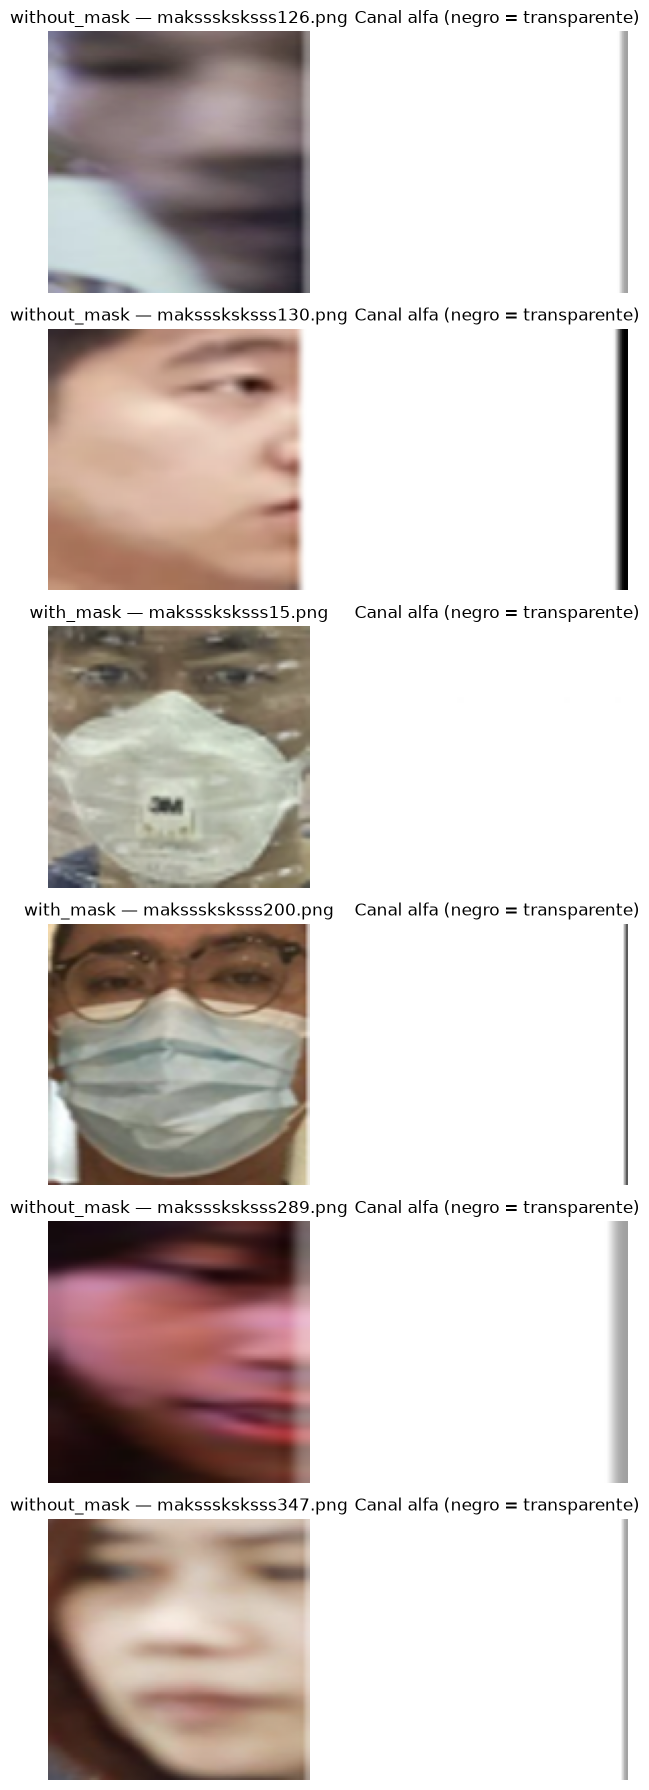

In [14]:
casos = transparencia_en_rostros[
    transparencia_en_rostros["pixeles_no_opacos"] > 0
]

fig, axes = plt.subplots(len(casos), 2, figsize=(7, 3 * len(casos)))

for fila_grafica, (indice, caso) in enumerate(casos.iterrows()):
    datos_rostro = rostros_conservados.iloc[indice]
    ruta = carpeta_imagenes / datos_rostro["imagen_original"]

    caja = (
        int(datos_rostro["xmin_analisis"]),
        int(datos_rostro["ymin_analisis"]),
        int(datos_rostro["xmax_analisis"]),
        int(datos_rostro["ymax_analisis"]),
    )

    with Image.open(ruta) as imagen:
        recorte = imagen.crop(caja).convert("RGBA")

        fondo = Image.new("RGBA", recorte.size, "white")
        sobre_blanco = Image.alpha_composite(fondo, recorte).convert("RGB")
        canal_alfa = recorte.getchannel("A")

    axes[fila_grafica, 0].imshow(sobre_blanco.resize((128, 128)))
    axes[fila_grafica, 0].set_title(
        f'{caso["clase"]} — {caso["imagen"]}'
    )

    axes[fila_grafica, 1].imshow(
        canal_alfa.resize((128, 128)),
        cmap="gray",
        vmin=0,
        vmax=255,
    )
    axes[fila_grafica, 1].set_title("Canal alfa (negro = transparente)")

    for eje in axes[fila_grafica]:
        eje.axis("off")

plt.tight_layout()
plt.show()

In [15]:
print(
    "Imágenes originales con rostros conservados:",
    rostros_conservados["imagen_original"].nunique()
)

print("\nImágenes que contienen cada clase:")
display(
    rostros_conservados
    .groupby("clase")["imagen_original"]
    .nunique()
    .rename("imagenes")
    .reset_index()
)

clases_por_imagen = (
    rostros_conservados
    .groupby("imagen_original")["clase"]
    .nunique()
)

print("\nCantidad de clases distintas por imagen:")
display(
    clases_por_imagen
    .value_counts()
    .sort_index()
    .rename_axis("clases_en_imagen")
    .reset_index(name="imagenes")
)

Imágenes originales con rostros conservados: 853

Imágenes que contienen cada clase:


,clase,imagenes
0,mask_weared_incorrect,94
1,with_mask,768
2,without_mask,270



Cantidad de clases distintas por imagen:


,clases_en_imagen,imagenes
0,1,613
1,2,201
2,3,39


In [16]:
combinaciones = (
    rostros_conservados
    .groupby("imagen_original")["clase"]
    .apply(lambda clases: " + ".join(sorted(set(clases))))
)

display(
    combinaciones
    .value_counts()
    .rename_axis("clases_presentes")
    .reset_index(name="imagenes")
)

,clases_presentes,imagenes
0,with_mask,532
1,with_mask + without_mask,167
2,without_mask,60
3,mask_weared_incorrect + with_mask + without_mask,39
4,mask_weared_incorrect + with_mask,30
5,mask_weared_incorrect,21
6,mask_weared_incorrect + without_mask,4


In [17]:
from sklearn.model_selection import train_test_split

tabla_imagenes = combinaciones.rename(
    "clases_presentes"
).reset_index()

tabla_imagenes["grupo_division"] = tabla_imagenes[
    "clases_presentes"
].apply(
    lambda texto: (
        "contiene_incorrecta"
        if "mask_weared_incorrect" in texto
        else texto
    )
)

train, temporal = train_test_split(
    tabla_imagenes,
    test_size=0.30,
    random_state=42,
    stratify=tabla_imagenes["grupo_division"],
)

validacion, prueba = train_test_split(
    temporal,
    test_size=0.50,
    random_state=42,
    stratify=temporal["grupo_division"],
)

asignaciones = pd.concat([
    train.assign(conjunto="entrenamiento"),
    validacion.assign(conjunto="validacion"),
    prueba.assign(conjunto="prueba"),
])

print("Imágenes por conjunto:")
display(asignaciones["conjunto"].value_counts())

print("\nGrupos por conjunto:")
display(
    pd.crosstab(
        asignaciones["grupo_division"],
        asignaciones["conjunto"],
    )
)

print(
    "\nImágenes asignadas una sola vez:",
    asignaciones["imagen_original"].is_unique,
)

Imágenes por conjunto:


conjunto
entrenamiento    597
validacion       128
prueba           128
Name: count, dtype: int64


Grupos por conjunto:


conjunto,entrenamiento,prueba,validacion
grupo_division,,,
contiene_incorrecta,66,14,14
with_mask,372,80,80
with_mask + without_mask,117,25,25
without_mask,42,9,9



Imágenes asignadas una sola vez: True


In [18]:
rostros_asignados = rostros_conservados.merge(
    asignaciones[["imagen_original", "conjunto"]],
    on="imagen_original",
    how="left",
    validate="many_to_one",
)

print(
    "Rostros sin conjunto:",
    rostros_asignados["conjunto"].isna().sum()
)

print("\nRostros por clase y conjunto:")
conteos = pd.crosstab(
    rostros_asignados["clase"],
    rostros_asignados["conjunto"],
)
display(conteos)

print("\nPorcentaje de cada clase dentro de cada conjunto:")
display((conteos / conteos.sum(axis=0) * 100).round(2))

print("\nTotal de rostros por conjunto:")
display(rostros_asignados["conjunto"].value_counts())

Rostros sin conjunto: 0

Rostros por clase y conjunto:


conjunto,entrenamiento,prueba,validacion
clase,,,
mask_weared_incorrect,83,19,16
with_mask,2035,388,454
without_mask,456,77,75



Porcentaje de cada clase dentro de cada conjunto:


conjunto,entrenamiento,prueba,validacion
clase,,,
mask_weared_incorrect,3.22,3.93,2.94
with_mask,79.06,80.17,83.30
without_mask,17.72,15.91,13.76



Total de rostros por conjunto:


conjunto
entrenamiento    2574
validacion        545
prueba            484
Name: count, dtype: int64

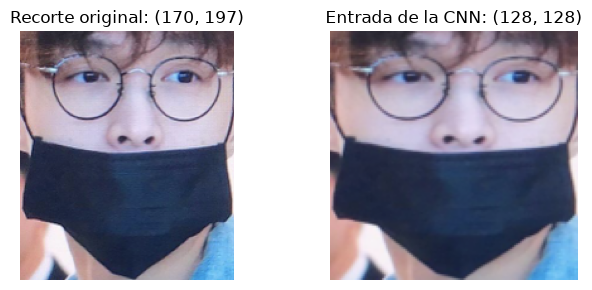

Clase: mask_weared_incorrect
Conjunto: entrenamiento

Total de rostros por conjunto:


conjunto
entrenamiento    2574
validacion        545
prueba            484
Name: count, dtype: int64

In [26]:

ejemplo = (
    rostros_asignados[
        rostros_asignados["clase"] == "mask_weared_incorrect"
    ]
    .sort_values("area_rostro", ascending=False)
    .iloc[0]
)

ruta = carpeta_imagenes / ejemplo["imagen_original"]

caja = (
    int(ejemplo["xmin_analisis"]),
    int(ejemplo["ymin_analisis"]),
    int(ejemplo["xmax_analisis"]),
    int(ejemplo["ymax_analisis"]),
)

with Image.open(ruta) as imagen:
    recorte = imagen.crop(caja).convert("RGBA")

    fondo = Image.new("RGBA", recorte.size, "white")
    recorte_rgb = Image.alpha_composite(
        fondo, recorte
    ).convert("RGB")

    entrada_modelo = recorte_rgb.resize(
        (128, 128),
        Image.Resampling.BILINEAR,
    )

fig, axes = plt.subplots(1, 2, figsize=(7, 3))

axes[0].imshow(recorte_rgb)
axes[0].set_title(f"Recorte original: {recorte_rgb.size}")

axes[1].imshow(entrada_modelo)
axes[1].set_title(f"Entrada de la CNN: {entrada_modelo.size}")

for eje in axes:
    eje.axis("off")

plt.tight_layout()
plt.show()

print("Clase:", ejemplo["clase"])
print("Conjunto:", ejemplo["conjunto"])
print("\nTotal de rostros por conjunto:")
display(rostros_asignados["conjunto"].value_counts())

In [24]:
from pathlib import Path

carpeta_procesada = Path(
    "/Users/eduardoabundiz/Desktop/face_mask_detection/data/processed"
)
carpeta_procesada.mkdir(parents=True, exist_ok=True)

# Una fila por imagen original: conserva la división reproducible
asignaciones.to_csv(
    carpeta_procesada / "splits.csv",
    index=False,
)

registros_procesados = []

for _, fila in rostros_asignados.iterrows():
    nombre_recorte = (
        f"{Path(fila['imagen_original']).stem}"
        f"_obj{int(fila['numero_objeto']):03d}.png"
    )

    carpeta_destino = (
        carpeta_procesada / fila["conjunto"] / fila["clase"]
    )
    carpeta_destino.mkdir(parents=True, exist_ok=True)
    ruta_destino = carpeta_destino / nombre_recorte

    caja = (
        int(fila["xmin_analisis"]),
        int(fila["ymin_analisis"]),
        int(fila["xmax_analisis"]),
        int(fila["ymax_analisis"]),
    )

    with Image.open(
        carpeta_imagenes / fila["imagen_original"]
    ) as imagen:
        recorte = imagen.crop(caja).convert("RGBA")
        fondo = Image.new("RGBA", recorte.size, "white")

        recorte_final = Image.alpha_composite(
            fondo, recorte
        ).convert("RGB").resize(
            (128, 128),
            Image.Resampling.BILINEAR,
        )

        recorte_final.save(ruta_destino)

    registros_procesados.append({
        "imagen_original": fila["imagen_original"],
        "numero_objeto": int(fila["numero_objeto"]),
        "clase": fila["clase"],
        "conjunto": fila["conjunto"],
        "ruta_recorte": str(ruta_destino),
        "xmin_original": int(fila["xmin"]),
        "ymin_original": int(fila["ymin"]),
        "xmax_original": int(fila["xmax"]),
        "ymax_original": int(fila["ymax"]),
        "xmax_utilizado": caja[2],
        "ymax_utilizado": caja[3],
    })

metadata_procesada = pd.DataFrame(registros_procesados)
metadata_procesada.to_csv(
    carpeta_procesada / "metadata.csv",
    index=False,
)

print("Recortes generados:", len(metadata_procesada))
print("Imágenes asignadas:", len(asignaciones))
print("Coordenadas xmax corregidas:", (
    metadata_procesada["xmax_original"]
    != metadata_procesada["xmax_utilizado"]
).sum())

Recortes generados: 3603
Imágenes asignadas: 853
Coordenadas xmax corregidas: 8


In [25]:
rutas_esperadas = set(
    metadata_procesada["ruta_recorte"]
)

rutas_en_disco = set(
    str(ruta)
    for ruta in carpeta_procesada.rglob("*.png")
)

archivos_faltantes = rutas_esperadas - rutas_en_disco
archivos_sobrantes = rutas_en_disco - rutas_esperadas

formatos_incorrectos = []

for ruta in rutas_esperadas:
    with Image.open(ruta) as imagen:
        if imagen.size != (128, 128) or imagen.mode != "RGB":
            formatos_incorrectos.append(
                (ruta, imagen.size, imagen.mode)
            )

print("Filas en metadata:", len(metadata_procesada))
print("Rutas únicas:", metadata_procesada["ruta_recorte"].nunique())
print("Archivos PNG en disco:", len(rutas_en_disco))
print("Archivos faltantes:", len(archivos_faltantes))
print("Archivos sobrantes:", len(archivos_sobrantes))
print("Tamaño o modo incorrecto:", len(formatos_incorrectos))

print("\nRecortes por conjunto y clase:")
display(
    pd.crosstab(
        metadata_procesada["clase"],
        metadata_procesada["conjunto"],
    )
)

Filas en metadata: 3603
Rutas únicas: 3603
Archivos PNG en disco: 3603
Archivos faltantes: 0
Archivos sobrantes: 0
Tamaño o modo incorrecto: 0

Recortes por conjunto y clase:


conjunto,entrenamiento,prueba,validacion
clase,,,
mask_weared_incorrect,83,19,16
with_mask,2035,388,454
without_mask,456,77,75
